# Crop Recommendation Model

A machine learning model that recommends the most suitable crop to grow based on soil nutrients and climate conditions.

### 1. Problem Statement
Farmers often choose crops based on experience rather than data. This project builds a classification model that predicts the best crop for a given piece of land using soil and weather measurements.

- **Type of problem:** Multi-class classification
- **Input:** Soil and climate features
- **Output:** Recommended crop name

### 2. Objectives
- Explore and understand the dataset
- Clean and prepare the data for modelling
- Train and compare multiple classification models
- Evaluate the models and select the best one
- Use the final model to make crop predictions

### 3. Dataset Description
- **Source:** "nishchalchandel/crop-recommendation"
- **Rows / columns:** 10 features and 3100 rows
- **Target column:** `crop` (crop name)

| Feature | Description | Unit |
|---|---|---|
| N | Nitrogen content in soil | ratio |
| P | Phosphorus content in soil | ratio |
| K | Potassium content in soil | ratio |
| temperature | Average temperature | °C |
| humidity | Relative humidity | % |
| rainfall | Rainfall | mm |
| ph | Soil pH value | pH scale |
| soil | Soil type | category |
| crop | Recommended crop | category |

---
## Load the Data
Loading the dataset and taking a first look at its structure (shape, column types, first few rows).

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [96]:
# Download and load the crop recommendation dataset.
%pip install -q kagglehub

import kagglehub
from pathlib import Path


dataset_path = Path(kagglehub.dataset_download("nishchalchandel/crop-recommendation"))
csv_files = list(dataset_path.rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError("No CSV file was found in the downloaded dataset.")

csv_file = csv_files[0]
df = pd.read_csv(csv_file)
print(f"Loaded {csv_file.name} from {dataset_path}")

Using Colab cache for faster access to the 'crop-recommendation' dataset.
Loaded crop_recommendation_dataset.csv from /kaggle/input/crop-recommendation


In [97]:
# Inspect the dataset shape, column types, rows, and missing values.
print("Shape:", df.shape)

print("\nColumn types:")
print(df.dtypes)

print("\nFirst few rows:")
display(df.head())

print("\nNull values by column:")
print(df.isna().sum())

Shape: (3100, 10)

Column types:
Temperature    float64
Humidity       float64
Rainfall       float64
PH             float64
Nitrogen       float64
Phosphorous    float64
Potassium      float64
Carbon         float64
Soil            object
Crop            object
dtype: object

First few rows:


,Temperature,Humidity,Rainfall,PH,Nitrogen,Phosphorous,Potassium,Carbon,Soil,Crop
0,20.879744,82.002744,202.935536,6.502985,69.30,79.50000,94.4400,0.63,Loamy Soil,rice
1,21.770462,80.319644,226.655537,7.038096,72.02,141.82400,141.6978,1.40,Loamy Soil,rice
2,23.004459,82.320763,263.964248,7.633568,77.77,59.39000,81.8900,1.80,Peaty Soil,rice
3,26.491096,80.283629,242.864034,6.980401,78.65,147.45895,142.9430,1.43,Loamy Soil,rice
4,20.280071,81.604873,262.717340,7.628473,73.98,68.95000,95.7400,1.75,Peaty Soil,rice



Null values by column:
Temperature    0
Humidity       0
Rainfall       0
PH             0
Nitrogen       0
Phosphorous    0
Potassium      0
Carbon         0
Soil           0
Crop           0
dtype: int64


---
## Data Cleaning
Renaming columns, removing unnecessary columns, checking for missing values, duplicates, and handling outliers in the dataset.

In [98]:
# rename the columns to have lowercase names and replace spaces with underscores. use N, P, K, instead of nitrogen, phosphorus, potassium.
df.columns = df.columns.str.lower().str.replace(' ', '_')
df = df.rename(columns={'nitrogen': 'N', 'phosphorous': 'P', 'potassium': 'K'})

In [99]:
# remove the feature carbon since it contains synthetic values and ambiguous unit.
df.drop(columns=['carbon'], inplace=True)

In [100]:
# Separate numerical and categorical features into two DataFrames.
df_num = df.select_dtypes(include="number").copy()
df_cat = df.select_dtypes(exclude="number").copy()

print("Numerical features:", df_num.shape)
print(df_num.dtypes)
print("\nCategorical features:", df_cat.shape)
print(df_cat.dtypes)

Numerical features: (3100, 7)
temperature    float64
humidity       float64
rainfall       float64
ph             float64
N              float64
P              float64
K              float64
dtype: object

Categorical features: (3100, 2)
soil    object
crop    object
dtype: object


In [101]:
# check for duplicate rows in the dataset.
duplicate_rows = df.duplicated()
print(f"Number of duplicate rows: {duplicate_rows.sum()}")

Number of duplicate rows: 0


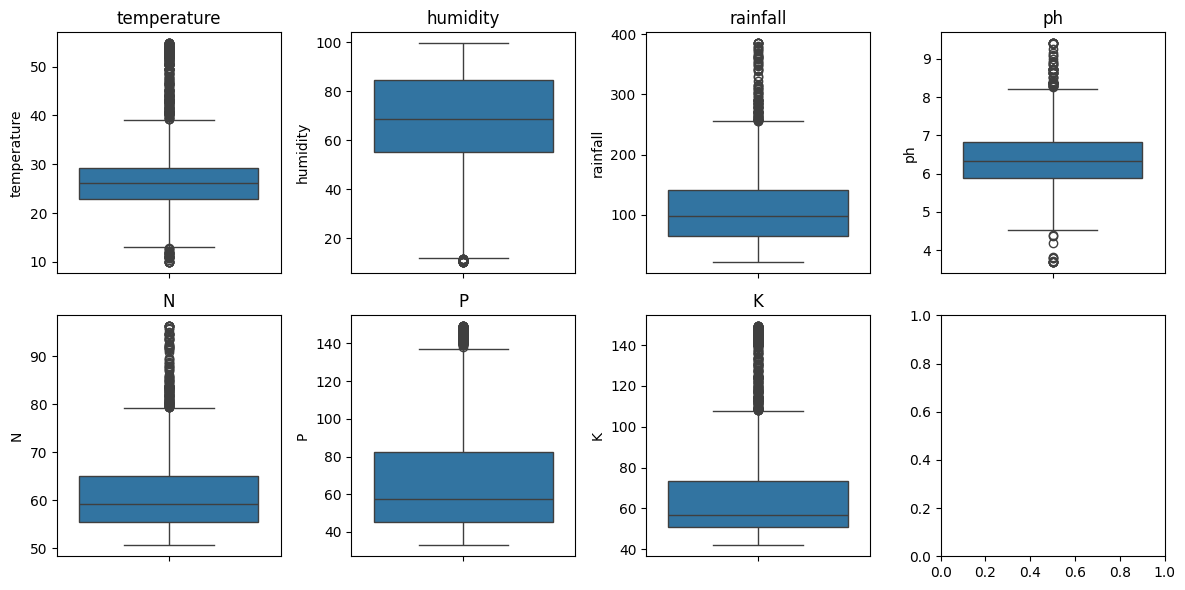

In [102]:
# draw a multiple boxplots, one for each numerical feature.
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

for i, column in enumerate(df_num.columns):
    row = i // 4
    col = i % 4
    sns.boxplot(data=df_num[column], ax=ax[row, col])
    ax[row, col].set_title(column)

plt.tight_layout()
plt.show()

In [103]:
# define a function to remove outliers using the IQR method.
def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]

In [104]:
# define a function to remove outliers using the Percentile method taking 99%ile.
def remove_outliers_percentile(df, column):
    lower_bound = df[column].quantile(0.005)
    upper_bound = df[column].quantile(0.995)
    return df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]

In [105]:
# use the remove_outliers_iqr function to remove outliers from each numerical feature in the dataset.
for column in df_num.columns:
    df = remove_outliers_iqr(df, column)

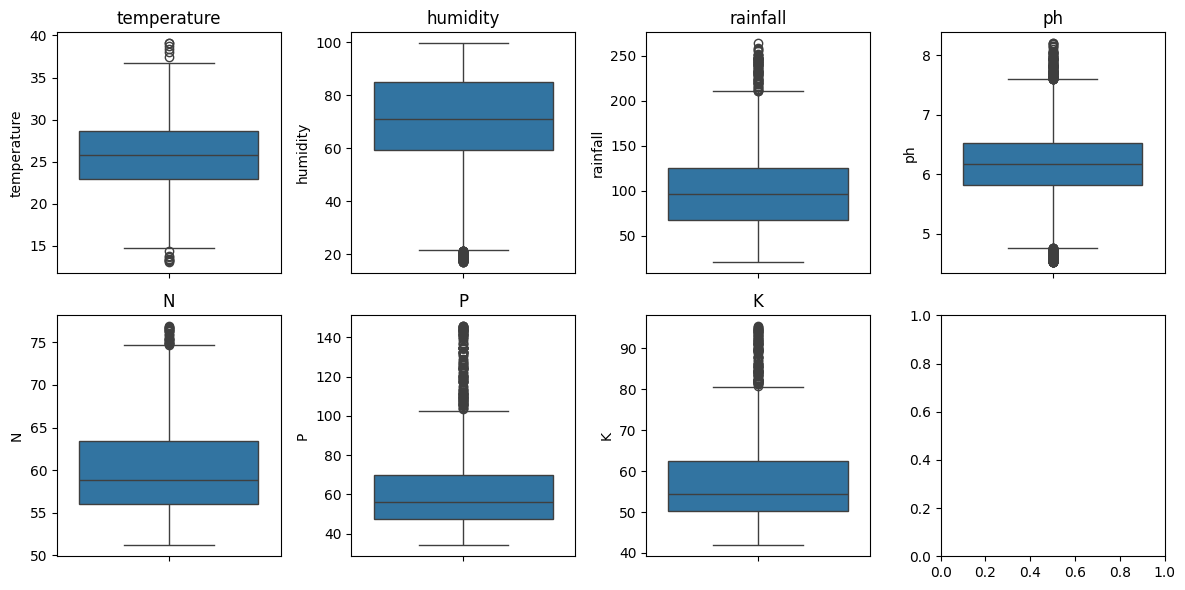

In [106]:
# recheck for outliers after removal by drawing boxplots again.
fig, ax = plt.subplots(2, 4, figsize=(12, 6))

for i, column in enumerate(df_num.columns):
    row = i // 4
    col = i % 4
    sns.boxplot(data=df[column], ax=ax[row, col])
    ax[row, col].set_title(column)

plt.tight_layout()
plt.show()

In [107]:
# display shape of the dataset after outlier removal.
print("Shape after outlier removal:", df.shape)

Shape after outlier removal: (2039, 9)


---
## Exploratory Data Analysis (EDA)
Understanding the data through statistics and plots.

In [108]:
# Display summary statistics for every numerical feature.
df_num = df.select_dtypes(include="number").copy()
display(df_num.describe().T)

,count,mean,std,min,25%,50%,75%,max
temperature,2039.0,25.852649,4.291092,13.058097,22.963084,25.832029,28.705250,39.065555
humidity,2039.0,69.937424,19.462974,16.988612,59.474314,71.189229,84.852153,99.646348
rainfall,2039.0,102.736354,50.137685,20.757078,67.944546,96.326010,125.091092,263.637218
ph,2039.0,6.210213,0.724526,4.523636,5.825383,6.181930,6.535351,8.203607
N,2039.0,60.099367,5.635175,51.180000,55.975000,58.790000,63.445000,76.880000
P,2039.0,61.623971,22.662272,33.989000,47.620000,56.200000,69.885000,145.610000
K,2039.0,57.829956,10.874443,41.860000,50.335000,54.380000,62.470000,95.360000


In [109]:
# Display summary statistics for every categorical feature.
df_cat = df.select_dtypes(exclude="number").copy()

for column in df_cat.columns:
    print(f"\n{column} summary:")
    display(df_cat[column].describe().to_frame())


soil summary:


,soil
count,2039
unique,5
top,Acidic Soil
freq,1246



crop summary:


,crop
count,2039
unique,28
top,Tea
freq,100


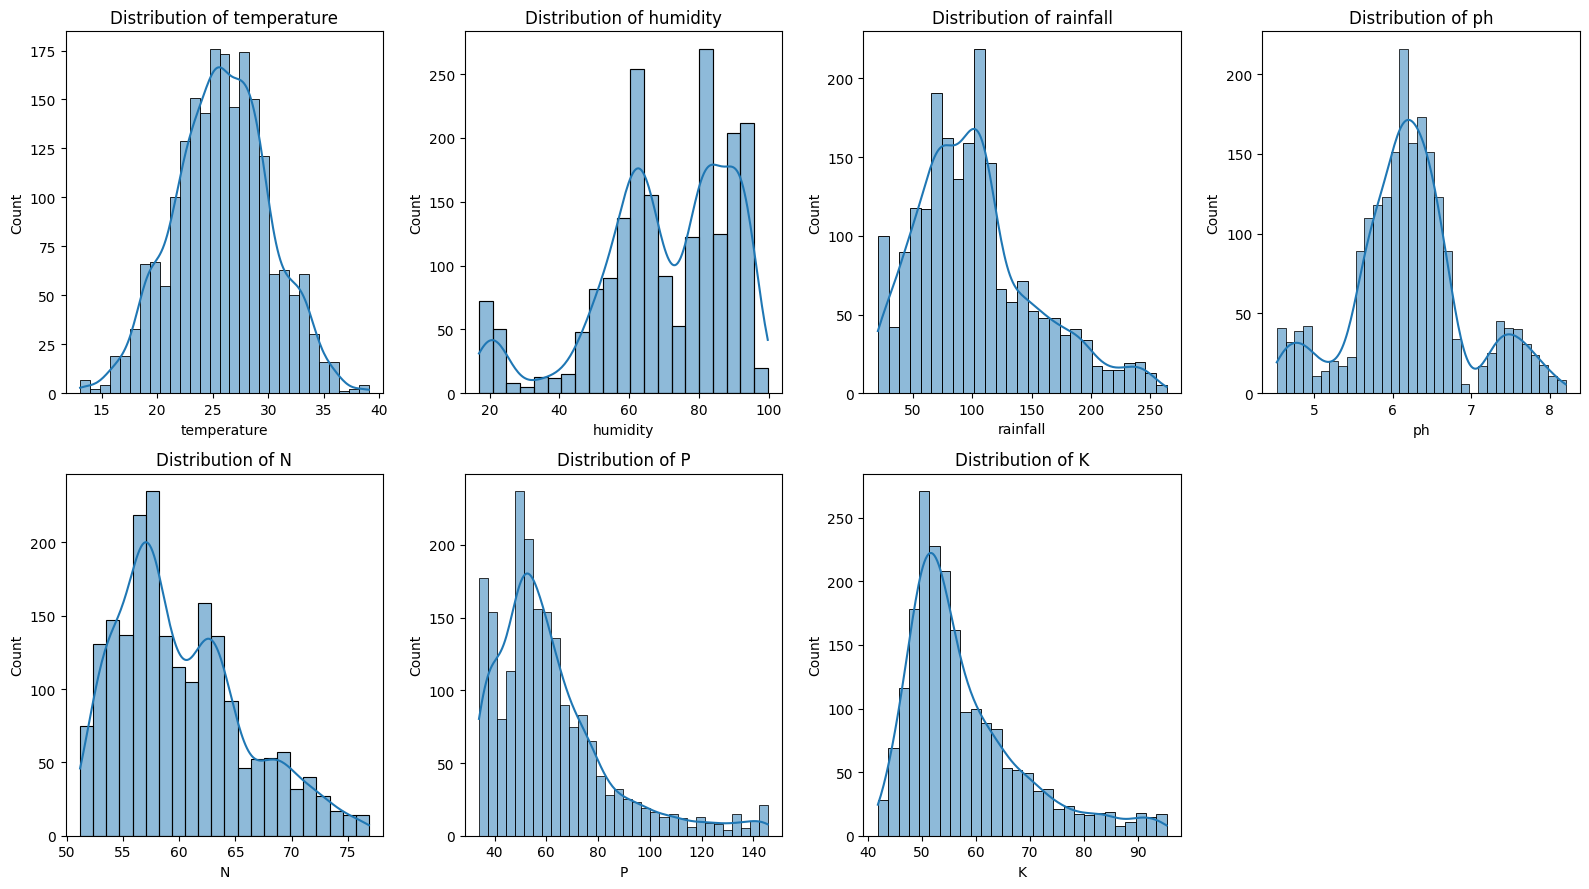

In [110]:
# Plot a histogram with KDE for each numerical feature.
fig, axes = plt.subplots(
    nrows=(len(df_num.columns) + 3) // 4,
    ncols=4,
    figsize=(16, 9),
)
axes = axes.flatten()

for index, column in enumerate(df_num.columns):
    sns.histplot(data=df_num, x=column, kde=True, ax=axes[index])
    axes[index].set_title(f"Distribution of {column}")

for axis in axes[len(df_num.columns):]:
    axis.set_visible(False)

plt.tight_layout()
plt.show()

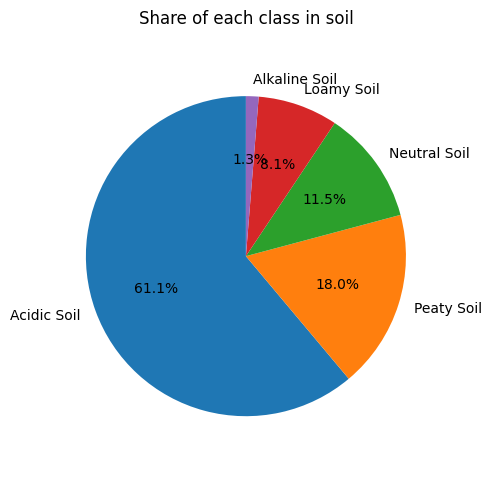

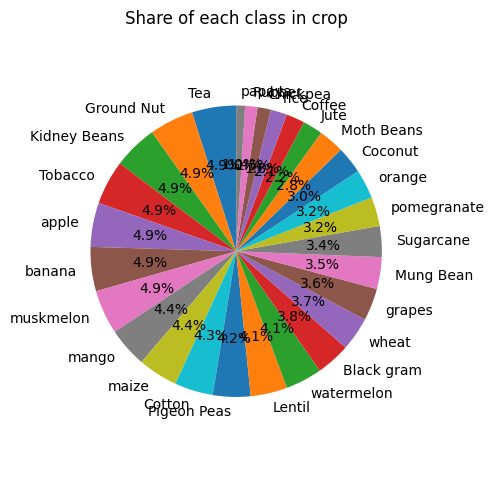

In [111]:
# Plot the class share for every categorical feature as a pie chart.
for column in df_cat.columns:
    class_counts = df_cat[column].value_counts()

    plt.figure(figsize=(5, 5))
    plt.pie(
        class_counts,
        labels=class_counts.index,
        autopct="%1.1f%%",
        startangle=90,
    )
    plt.title(f"Share of each class in {column}")
    plt.axis("equal")
    plt.tight_layout()
    plt.show()

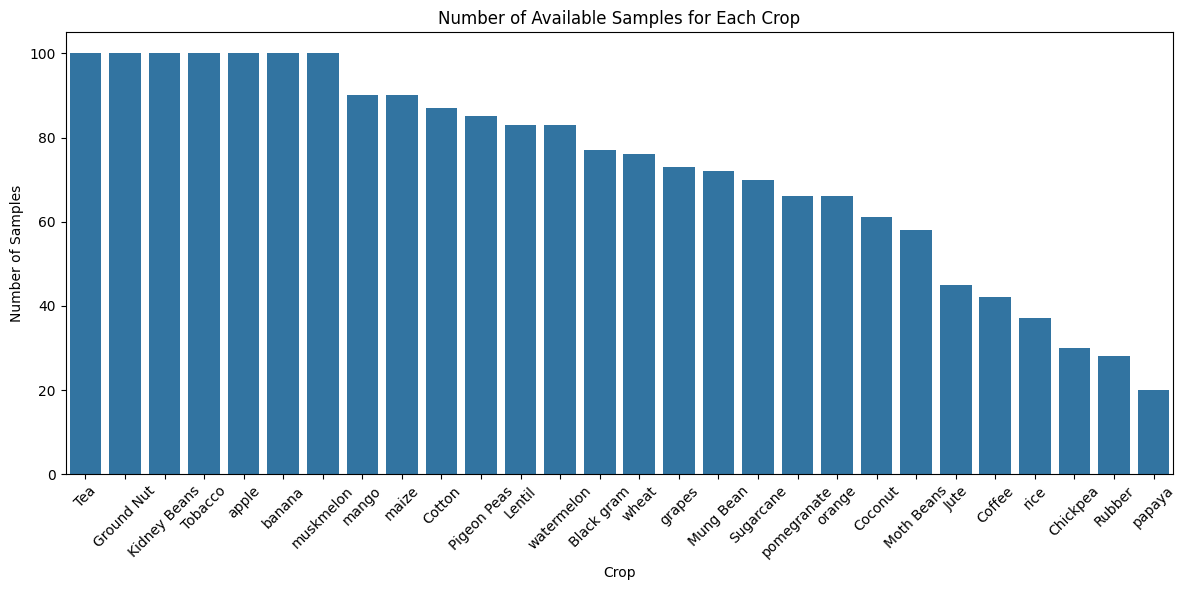

In [112]:
# Plot the number of available samples for each crop.
if "crop" not in df.columns:
    raise KeyError("The dataset must contain a 'crop' column.")

crop_counts = df["crop"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=crop_counts.index, y=crop_counts.values)
plt.title("Number of Available Samples for Each Crop")
plt.xlabel("Crop")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()